# Linear Regression Playbook

## Setup

In [1]:
!python --version

Python 3.12.15


In [37]:
!cat requirements.txt

# Linear Regression Requirements
# Python 3.12.x
numpy==2.5.3
pandas==2.3.3
scikit-learn==1.6.1
matplotlib==3.10.6
seaborn==0.13.2


In [3]:
!python -m pip install -q -r requirements.txt

### Imports

In [55]:
import numpy as np
import pandas as pd
from zipfile import ZipFile
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import math

### Configurations

In [35]:
sns.set_theme(style="darkgrid")

In [36]:
%matplotlib inline

## Linear Regression

In [25]:
class LinearRegression:
    def __init__(self):
        self.w = None
        self.b = None

    def fit(self, X: np.ndarray, y: np.ndarray, lr: float = 0.01, epochs: int = 1000, silent: bool = False):
        # 1) Let X be the input features of size NxD, where N is the number of training samples 
        # and D is the number of features.
        N, D = X.shape

        # 2) Initialize the weights (w) to zeros (can also be random values)
        self.w = np.zeros(D) # Weights are of size D

        # 3) Initialize the bias (b) to zero (can also be random value)
        self.b = 0

        # 4) Begin gradient descent loop
        for epoch in range(epochs):
            # a) Compute the predictions (y_pred) using the current weights and bias
            y_pred = np.dot(X, self.w) + self.b

            # b) Compute the loss (mean squared error)
            loss = np.mean((y_pred - y) ** 2)

            # c) Determine the direction of the gradient for weights and bias
            dw = (2/N) * np.dot(X.T, (y_pred - y))
            db = (2/N) * np.sum(y_pred - y)

            # d) Update the weights and bias using the gradients and learning rate (larger weights can cause overfitting)
            self.w -= lr * dw
            self.b -= lr * db

            # Optional: Print loss every 100 epochs
            if epoch % 100 == 0 and not silent:
                print(f'Epoch {epoch}, Loss: {loss}')

    def predict(self, X: np.ndarray) -> np.ndarray:
        # 1) Compute the predictions (y_pred) using the learned weights and bias
        y_pred = np.dot(X, self.w) + self.b
        return y_pred


## Dataset
USA Housing dataset from Kaggle: https://www.kaggle.com/datasets/vedavyasv/usa-housing?resource=download

In [6]:
!du -sh USA_Housing_Dataset.zip

364K	USA_Housing_Dataset.zip


In [9]:
# Extract the dataset from the zip file if it hasn't been extracted yet
with ZipFile('USA_Housing_Dataset.zip', 'r') as zip_ref:
    zip_ref.extractall()

In [10]:
!ls *.csv

USA_Housing.csv


In [13]:
# Load and inspect the dataset
data = pd.read_csv('USA_Housing.csv')
data.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [15]:
data.shape

(5000, 7)

In [14]:
data.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


### Data Prep

In [16]:
# Separate features and target variable, "Price"
target_col = 'Price'
X = data.drop(columns=[target_col]).values
y = data[target_col].values

In [21]:
# Only keep numeric features for linear regression
numeric_cols = data.select_dtypes(include=[np.number]).columns.tolist()
X = data[numeric_cols].drop(columns=[target_col]).values

print(f'Dropped non-numeric cols: {set(data.columns) - set(numeric_cols)}')

Dropped non-numeric cols: {'Address'}


In [30]:
X.shape

(5000, 5)

In [22]:
# Scale the features (X)
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

In [33]:
# Select optimal features for linear regression using PCA (Principal Component Analysis)
pca = PCA(n_components=5)  # Adjust the number of components as needed

# Fit PCA on the scaled features and transform them
X_pca = pca.fit_transform(X_scaled)

# Print the explained variance ratio for each component
print(f'Explained Variance Ratio: {pca.explained_variance_ratio_}')

Explained Variance Ratio: [0.29264726 0.20502271 0.20041714 0.19481882 0.10709407]


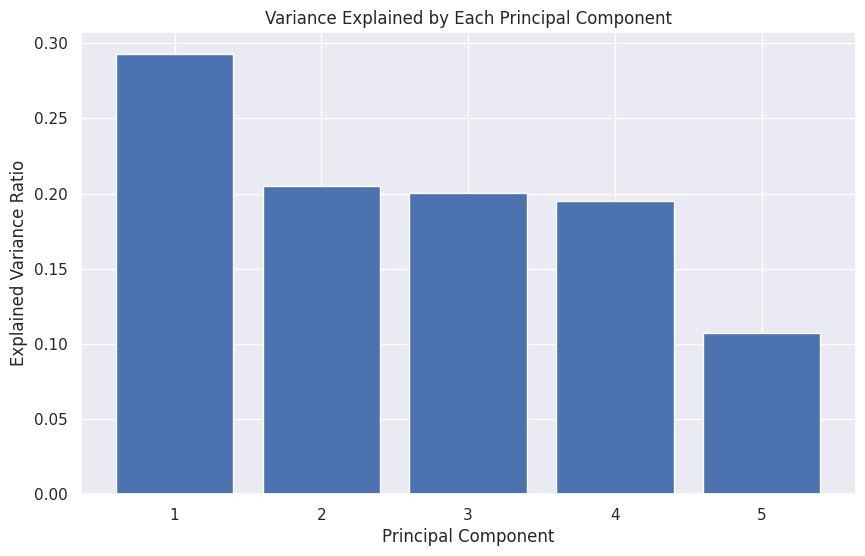

In [38]:
# Plot the explained variance ratio to visualize how much variance each principal component captures
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Variance Explained by Each Principal Component')
plt.show()

In [46]:
# Select features based on PCA results (for example, the first 4 components)
X_selected = pca.transform(X_scaled)[:, :4]

In [47]:
# Scale the selected features (X_selected)
# scaler_selected = StandardScaler()
# X_selected_scaled = scaler_selected.fit_transform(X_selected)

In [48]:
# Inspect sample of original features vs. scaled features vs. selected features vs. scaled selected features
print("Original features (sample):")
print(X[:5])

print("\nScaled features (sample):")
print(X_scaled[:5])

print("\nSelected features (sample):")
print(X_selected[:5])

# print("\nScaled selected features (sample):")
# print(X_selected_scaled[:5])

Original features (sample):
[[7.95454586e+04 5.68286132e+00 7.00918814e+00 4.09000000e+00
  2.30868005e+04]
 [7.92486425e+04 6.00289981e+00 6.73082102e+00 3.09000000e+00
  4.01730722e+04]
 [6.12870672e+04 5.86588984e+00 8.51272743e+00 5.13000000e+00
  3.68821594e+04]
 [6.33452400e+04 7.18823609e+00 5.58672866e+00 3.26000000e+00
  3.43102428e+04]
 [5.99821972e+04 5.04055452e+00 7.83938779e+00 4.23000000e+00
  2.63541095e+04]]

Scaled features (sample):
[[ 1.02865969 -0.29692705  0.02127433  0.08806222 -1.31759867]
 [ 1.00080775  0.02590164 -0.25550611 -0.72230146  0.40399945]
 [-0.68462916 -0.11230283  1.5162435   0.93084045  0.07240989]
 [-0.49149907  1.22157207 -1.39307717 -0.58453963 -0.18673422]
 [-0.80707253 -0.94483368  0.84674187  0.20151314 -0.98838741]]

Selected features (sample):
[[ 0.13432129 -1.26068758  0.96090041 -0.59866803]
 [-0.68943201 -0.18791729  0.74021139  0.75004554]
 [ 1.71720017  0.49743785 -0.47099253 -0.30491894]
 [-1.4030036  -0.61533774 -1.14620534  0.28040

## Train

### Baseline Training

In [51]:
# Initialize and train the linear regression model
model = LinearRegression()
model.fit(X_scaled, y, lr=0.01, epochs=1000)

Epoch 0, Loss: 1642670144875.993
Epoch 100, Loss: 39394023261.4573
Epoch 200, Loss: 10788824122.807898
Epoch 300, Loss: 10235976521.780508
Epoch 400, Loss: 10220737509.344978
Epoch 500, Loss: 10219835130.55916
Epoch 600, Loss: 10219745739.182716
Epoch 700, Loss: 10219735634.704868
Epoch 800, Loss: 10219734466.566109
Epoch 900, Loss: 10219734331.04879


### Baseline Evaluation
**NOTE:** Training on 4 pricipal components reslts in a lower R² score so we stick with scaled features for this use case.

In [60]:
def evaluate(model, X, y):
    # Make predictions on the training data
    y_pred = model.predict(X)

    # Calculate Mean Squared Error (MSE)
    mse = np.mean((y_pred - y) ** 2)

    # Calculate Root Mean Squared Error (RMSE)
    rmse = np.sqrt(mse)

    # Calculate Mean Absolute Error (MAE)
    mae = np.mean(np.abs(y_pred - y))

    # Calculate R-squared (coefficient of determination)
    ss_total = np.sum((y - np.mean(y)) ** 2)
    ss_residual = np.sum((y - y_pred) ** 2)
    r_squared = 1 - (ss_residual / ss_total)

    print(f'Mean Squared Error      : {mse}')
    print(f'Root Mean Squared Error : ${round(rmse, 2):,}')
    print(f'Mean Absolute Error     : ${round(mae, 2):,}')
    print(f'R-squared               : {r_squared}')

In [61]:
# Evaluate the model's performance on the training data
evaluate(model, X_scaled, y)

Mean Squared Error      : 10219734315.3188
Root Mean Squared Error : $101,092.7
Mean Absolute Error     : $81,359.29
R-squared               : 0.9180238194923849


## Next Steps
To get better results with the custom linear regression model we can do the following:
* Check residuals against the predictions to spot nonlinearity or outliers. For instance, `Price` has a minimum of about $16k, which looks odd.
* Compare against closed-form least squares (np.linalg.lstsq). If gradient descent matches it, the model is optimal for these features, and the remaining error is noise the linear model can't capture.
* Evaluate on a held-out test set so the numbers aren't training-only.